# Data Engineering: Big Data Processing on One Machine

> **Who is this for:** you know basic Python and pandas, and you have heard words like "MapReduce", "Parquet", "Spark" or "out of memory" without being sure what they mean in practice. It is also for students taking a "Big Data Analytics" or "Parallel and Distributed Computing" course, and for data-engineering / ML-engineering interviews ("how would you process a 200 GB file on a 16 GB laptop?").
>
> **What you will learn:**
> - What "big" really means: memory vs disk vs cluster, and **back-of-envelope sizing**
> - **MapReduce from scratch** (map, shuffle, reduce) with `multiprocessing`: word count, inverted index, join and group-by, plus the **combiner** optimisation
> - **Out-of-core pandas**: `chunksize` aggregations, dtype optimisation, categoricals, and memory measurement with `psutil`
> - **Columnar storage**: Parquet row groups, statistics, **partitioning by date**, predicate pushdown and column pruning, with measured speedups
> - **DuckDB** (and optionally **Polars**) lazy queries on data larger than the engine's memory limit: spilling and streaming execution
> - **Data skew**, partition sizing and **salting**; the external merge sort idea
> - A tiny **task-graph scheduler** (what Dask does), plus the real Dask version when it is installed
> - When to move up from pandas to Polars, DuckDB, Dask or Spark
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [pandas](../../02_Data_Analysis/03_pandas.ipynb); [DuckDB](../../02_Data_Analysis/10_duckdb.ipynb) and [Polars](../../02_Data_Analysis/09_polars.ipynb) are helpful; [Data engineering for ML](01_data_engineering.ipynb) (ETL, the modern data stack); [hashing](../../00_AI_Fundamentals/dsa/04_hashing.ipynb); [storage and recovery](../00_dbms_fundamentals/06_recovery_and_storage.ipynb) and [query processing](../00_dbms_fundamentals/08_query_processing_and_optimization.ipynb) from the DBMS track.
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. Everything is generated into a temporary folder that is deleted at the end. The whole notebook runs in about one to two minutes. **Dask and Polars are optional**: their cells are skipped with a one-line message if they are not installed, and every idea is also shown with pure Python, pandas, `multiprocessing`, PyArrow or DuckDB.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Leskovec, Rajaraman & Ullman, *Mining of Massive Datasets* (ch. 2, MapReduce) and Kleppmann, *Designing Data-Intensive Applications* (ch. 3 and 10).

## Explained simply

"Big data" just means data that is too large to handle the easy way: it does not fit in your computer's memory (RAM), or one CPU core would take far too long to go through it. There are only a few tricks to deal with it, and this notebook builds each one by hand. **Split** the work into pieces and give the pieces to several workers at once (that is MapReduce, the idea behind Hadoop and Spark). **Stream** the data through memory a slice at a time instead of loading it all. **Store** it cleverly, by column and in labelled folders, so you can skip most of it without even reading it (that is Parquet). Think of a school counting votes: instead of one teacher counting 10,000 ballots, ten classes each count a pile, then one person adds up the ten totals. Or think of a library: if books are shelved by subject and year, you walk straight to "Physics, 2024" instead of reading every shelf.

**Tiny example.** Count the words in two sentences, "cat sat" and "cat ran". Worker 1 takes sentence 1 and writes down `cat:1, sat:1`. Worker 2 takes sentence 2 and writes `cat:1, ran:1`. Then all the `cat` notes go to one pile, `sat` to another, `ran` to a third (that is the **shuffle**). Adding each pile gives `cat:2, sat:1, ran:1`. Nobody ever had to look at all the data at once.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| MapReduce | split the work, process pieces in parallel, then combine by key | Hadoop, Spark, counting tokens in an LLM training corpus |
| Out-of-core processing | read a big file a slice at a time so memory stays small | pandas `chunksize`, DuckDB spilling to disk |
| Parquet + partitioning | store data by column in labelled folders so most of it can be skipped | data lakes, feature stores, Hugging Face datasets |

### How this notebook is different from `01_data_engineering`
[`01_data_engineering`](01_data_engineering.ipynb) gives the map of the field (ETL vs ELT, Spark, Kafka, dbt, Airflow, Delta Lake) as concepts. Here we **run** the core big-data techniques on one machine, from scratch, and measure them. [`02_Data_Analysis/10_duckdb`](../../02_Data_Analysis/10_duckdb.ipynb) teaches DuckDB SQL; here DuckDB appears only as an *out-of-core engine* (memory limits, spilling, pushdown). Spark itself is in [03 · Spark locally](03_spark_locally.ipynb), and streams are in [04 · Stream processing from scratch](04_stream_processing_from_scratch.ipynb).

## Table of contents
0. Setup
1. What "big" means: back-of-envelope sizing
2. MapReduce from scratch
3. Out-of-core pandas: chunks, dtypes and memory
4. Columnar storage: Parquet, row groups and partitioning
5. DuckDB (and Polars) on data larger than the memory limit
6. Data skew, partition sizing and salting
7. External merge sort: sorting more data than fits in memory
8. Task graphs: a mini-Dask, and real Dask (optional)
9. Choosing a tool: pandas, Polars, DuckDB, Dask, Spark
10. How this connects to modern AI
11. Recap, practice problems, further reading

---
## 0. Setup

We use only libraries that are already installed: the standard library, NumPy, pandas, matplotlib, PyArrow (the Parquet engine pandas uses), DuckDB and psutil. Polars and Dask are detected but not required.

In [1]:
import os, sys, time, json, zlib, shutil, tempfile, heapq, subprocess, importlib.util
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pacsv
import pyarrow.parquet as pq
import pyarrow.dataset as ds
import duckdb
import psutil

HAS_POLARS = importlib.util.find_spec("polars") is not None   # optional
HAS_DASK = importlib.util.find_spec("dask") is not None       # optional

WORK = Path(tempfile.mkdtemp(prefix="bigdata_"))   # everything we write goes here; deleted at the end
RNG = np.random.default_rng(42)                    # one seeded generator for reproducible data
N_WORKERS = min(4, os.cpu_count() or 1)            # small pool: be kind to shared machines

def timed(fn, *args, repeat=1, **kw):
    # Run fn and return (result, best wall-clock seconds over `repeat` runs).
    best, out = float("inf"), None
    for _ in range(repeat):
        t0 = time.perf_counter()
        out = fn(*args, **kw)
        best = min(best, time.perf_counter() - t0)
    return out, best

def folder_mb(path):
    # Total size of all files below `path`, in MB.
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file()) / 1e6

print("pandas", pd.__version__, "| pyarrow", pa.__version__, "| duckdb", duckdb.__version__)
print("polars installed:", HAS_POLARS, "| dask installed:", HAS_DASK)
print("CPU cores:", os.cpu_count(), "| workers we will use:", N_WORKERS)

pandas 2.3.3 | pyarrow 24.0.0 | duckdb 1.5.4
polars installed: False | dask installed: False
CPU cores: 8 | workers we will use: 4


---
## 1. What "big" means: back-of-envelope sizing

> 💬 **In plain English:** work out whether your data fits in memory with simple multiplication before choosing any tool.

Data is "big" relative to the machine. The question is always: **does it fit, and how long does one pass take?**

There are three levels, each roughly 10–100× bigger and slower than the one before:

```
   fits in RAM            fits on local disk           needs many machines
 ┌──────────────┐       ┌───────────────────┐       ┌──────────────────────┐
 │ 1–64 GB      │       │ 0.5–8 TB SSD      │       │ PB across a cluster  │
 │ ~10–50 GB/s  │  -->  │ ~0.5–7 GB/s read  │  -->  │ network ~1–25 GB/s   │
 │ pandas/numpy │       │ chunks, Parquet,  │       │ Spark, Dask cluster, │
 │              │       │ DuckDB, Polars    │       │ BigQuery, Snowflake  │
 └──────────────┘       └───────────────────┘       └──────────────────────┘
```

A **back-of-envelope estimate** multiplies rows × bytes per row. The fixed-width types are easy: `int64`/`float64` are 8 bytes, `int32`/`float32` 4, `bool`/`int8` 1. Strings are the trap: a pandas `object` column stores a pointer (8 bytes) **plus** a full Python string object (41 bytes of overhead in Python 3.12+, 49 in older versions, plus 1 byte per ASCII character). The same column as a **categorical** stores a small integer code per row plus each distinct string once.

| what | rows | bytes per row | size |
|---|---|---|---|
| 1 billion clicks: 3 × int64 + 1 × float64 | $10^9$ | 32 | 32 GB |
| same, plus a 10-char `object` string column | $10^9$ | 32 + 8 + 41 + 10 = 91 | ≈ 91 GB |
| same string as a categorical with 100 values (1-byte codes) | $10^9$ | 32 + 1 | ≈ 33 GB |

Rule of thumb from the pandas author (Wes McKinney): pandas wants **5–10× the dataset size in RAM** while you work, because operations create copies.

In [2]:
def estimate_bytes(n_rows, schema):
    # schema: dict column -> type name. Returns an estimated in-memory size in bytes.
    per_value = {"int64": 8, "float64": 8, "int32": 4, "float32": 4, "int8": 1, "bool": 1,
                 "datetime64": 8, "category": 1}              # category: 1-byte codes if < 128 values
    total = 0
    for col, typ in schema.items():
        if typ.startswith("str"):                             # 'str10' = object string of 10 chars
            n_chars = int(typ[3:])
            total += n_rows * (8 + 41 + n_chars)              # pointer + Python 3.12 str header + chars
        else:
            total += n_rows * per_value[typ]
    return total

# Check the estimate against what pandas actually allocates for 200,000 rows.
n = 200_000
demo = pd.DataFrame({
    "user_id": RNG.integers(0, 10**6, n),                     # int64
    "amount": RNG.random(n),                                  # float64
    "country": RNG.choice(["PK", "US", "IN", "DE", "BR"], n), # 2-char strings, object dtype
})
demo["country"] = demo["country"].astype(object)
est = estimate_bytes(n, {"user_id": "int64", "amount": "float64", "country": "str2"})
real = demo.memory_usage(deep=True, index=False).sum()
print(f"estimated {est/1e6:.1f} MB, pandas reports {real/1e6:.1f} MB")
print(f"as categorical: {demo.astype({'country': 'category'}).memory_usage(deep=True, index=False).sum()/1e6:.1f} MB")

# Scale the estimate to a 'big' table and compare with this machine.
big = estimate_bytes(10**9, {"user_id": "int64", "item_id": "int64", "ts": "int64", "amount": "float64", "country": "str10"})
ram = psutil.virtual_memory().total
print(f"1e9-row click table ≈ {big/1e9:.0f} GB in pandas; this machine has {ram/1e9:.0f} GB RAM "
      f"-> fits in RAM with pandas' 5-10x working space? {big*5 < ram}")

estimated 13.4 MB, pandas reports 13.4 MB
as categorical: 3.4 MB
1e9-row click table ≈ 91 GB in pandas; this machine has 25 GB RAM -> fits in RAM with pandas' 5-10x working space? False


**What just happened?** The formula predicts pandas' own memory report exactly (13.4 MB). The string column costs more than both numeric columns together, and the categorical version is about four times smaller. The 1-billion-row table is about 91 GB in pandas, so on a normal machine it does **not** fit, even before pandas' working copies. That is exactly when you reach for the techniques below.

> 🎓 **Exam / interview tip:** when asked "how would you process X GB?", start with the arithmetic: rows × bytes per row, compare to RAM, then estimate one full pass as size ÷ disk bandwidth (e.g. 200 GB ÷ 2 GB/s ≈ 100 s). Interviewers want to see the estimate before the tool choice.

---
## 2. MapReduce from scratch

> 💬 **In plain English:** split the data, let several workers process their piece, send each key to one place, and add up per key.

**MapReduce** (Dean & Ghemawat, Google, 2004) is a programming model for processing large data sets in parallel. You write only two small functions, and the framework does the rest:

- **map**$(record) \to$ a list of (key, value) pairs,
- **reduce**$(key, [values]) \to$ output for that key.

Between them, the framework performs the **shuffle**: every pair is sent to reducer number $\text{hash}(key) \bmod R$, and each reducer **groups** its pairs by key. Because all values for one key end up on the same reducer, each reducer can work independently.

```
 input splits        MAP              SHUFFLE (partition by hash(key) % R)        REDUCE
 ┌──────────┐   (cat,1)(sat,1)  ──┐                                      ┌─> cat: [1,1] -> 2
 │ "cat sat"│ ─────────────────── ├──> reducer 0 gets every 'cat', 'ran' ─┤
 └──────────┘                     │                                      └─> ran: [1]   -> 1
 ┌──────────┐   (cat,1)(ran,1)  ──┤
 │ "cat ran"│ ───────────────────  └──> reducer 1 gets every 'sat' ────────> sat: [1]   -> 1
 └──────────┘
```

Worked by hand (word count, $R = 2$, suppose `hash('cat') % 2 = 0`, `hash('ran') % 2 = 0`, `hash('sat') % 2 = 1`):

| phase | worker | data |
|---|---|---|
| map | mapper 1 | (cat,1), (sat,1) |
| map | mapper 2 | (cat,1), (ran,1) |
| shuffle | reducer 0 receives | (cat,1), (cat,1), (ran,1) → groups cat:[1,1], ran:[1] |
| shuffle | reducer 1 receives | (sat,1) → group sat:[1] |
| reduce | output | cat 2, ran 1, sat 1 |

A **combiner** is a "mini-reducer" that runs on each mapper's output *before* the shuffle (mapper 1 would send `(cat, 3)` instead of three `(cat, 1)` pairs). It is only correct when the reduce function is **associative and commutative** (sum, max, min, count), and it can cut network traffic enormously.

### 2.1 The engine

`multiprocessing` sends functions to worker processes by **pickling their name** and re-importing them, so on Windows and macOS (and on Linux from Python 3.14, where the default start method changed) functions defined inside a notebook cannot be sent to workers. The robust pattern is to put worker functions in a small module. The next cell writes our engine to a file in the temp folder (it is still plain Python you can read) and imports it.

In [3]:
MR_FILE = WORK / "minimr.py"
MR_FILE.write_text('''
# minimr: a tiny MapReduce engine (map -> shuffle -> reduce) on multiprocessing.
import zlib
from itertools import groupby
from operator import itemgetter

def partition_of(key, n_reducers):
    # Deterministic partitioner. Python's hash() of a str changes between processes, crc32 does not.
    return zlib.crc32(repr(key).encode()) % n_reducers

def _group(pairs):
    # Sort pairs by key and yield (key, [values]) groups: the "group" half of the shuffle.
    pairs.sort(key=itemgetter(0))
    for key, grp in groupby(pairs, key=itemgetter(0)):
        yield key, [v for _, v in grp]

def map_task(args):
    # One map task: run the mapper over one input split and bucket its output by reducer.
    split, mapper, combiner, n_reducers = args
    buckets = [[] for _ in range(n_reducers)]       # one outgoing list per reducer
    emitted = 0
    for record in split:
        for key, value in mapper(record):
            buckets[partition_of(key, n_reducers)].append((key, value))
            emitted += 1
    if combiner is not None:                        # local pre-aggregation before the shuffle
        buckets = [[kv for k, vs in _group(b) for kv in combiner(k, vs)] for b in buckets]
    return buckets, emitted

def reduce_task(args):
    # One reduce task: group everything this reducer received by key and call the reducer.
    pairs, reducer = args
    return [out for key, values in _group(pairs) for out in reducer(key, values)]

def run_mapreduce(splits, mapper, reducer, n_reducers=4, combiner=None, pool=None):
    # Run a whole job. With pool=None everything runs in this process (handy for debugging).
    run = pool.map if pool is not None else map
    map_out = list(run(map_task, [(s, mapper, combiner, n_reducers) for s in splits]))
    # SHUFFLE: reducer r receives bucket r from every mapper
    inbox = [[kv for buckets, _ in map_out for kv in buckets[r]] for r in range(n_reducers)]
    stats = {"map_tasks": len(splits),
             "map_output_records": sum(e for _, e in map_out),
             "shuffled_records": sum(len(b) for b in inbox),
             "records_per_reducer": [len(b) for b in inbox]}
    results = [out for part in run(reduce_task, [(b, reducer) for b in inbox]) for out in part]
    return results, stats

# ---------------- example jobs ----------------
def wc_map(line):                 # word count: (word, 1) per word
    for word in line.split():
        yield word, 1

def wc_reduce(word, counts):      # sum is associative + commutative, so it can also be the combiner
    yield word, sum(counts)

def ii_map(doc):                  # inverted index: doc = (doc_id, text) -> (word, doc_id)
    doc_id, text = doc
    for word in set(text.split()):
        yield word, doc_id

def ii_reduce(word, doc_ids):     # posting list = sorted unique doc ids
    yield word, sorted(set(doc_ids))

def join_map(record):             # reduce-side join: tag each record with its table
    if record[0] == "U":          # ("U", user_id, country)
        yield record[1], ("U", record[2])
    else:                         # ("O", order_id, user_id, amount)
        yield record[2], ("O", record[1], record[3])

def join_reduce(user_id, tagged): # all rows of both tables for one user meet here
    countries = [t[1] for t in tagged if t[0] == "U"]
    orders = [t for t in tagged if t[0] == "O"]
    for c in countries:           # inner join = cross product of the two sides for this key
        for _, order_id, amount in orders:
            yield order_id, user_id, c, amount

def avg_map(row):                 # group-by average: emit (country, (amount, 1))
    country, amount = row
    yield country, (amount, 1)

def avg_combine(country, pairs):  # CORRECT combiner: add sums and counts separately
    yield country, (sum(a for a, _ in pairs), sum(c for _, c in pairs))

def avg_combine_wrong(country, pairs):   # WRONG combiner: pre-averages, then forgets the count
    yield country, (sum(a for a, _ in pairs) / len(pairs), 1)

def avg_reduce(country, pairs):
    total, count = sum(a for a, _ in pairs), sum(c for _, c in pairs)
    yield country, total / count
''')

sys.path.insert(0, str(WORK))      # make the module importable here and in spawned workers
import minimr
print("engine written to the temp folder and imported:", [f for f in dir(minimr) if f.endswith(("_map", "_reduce"))])

engine written to the temp folder and imported: ['avg_map', 'avg_reduce', 'ii_map', 'ii_reduce', 'join_map', 'join_reduce', 'wc_map', 'wc_reduce']


### 2.2 Word count, sequential vs parallel

We generate a synthetic corpus whose word frequencies follow **Zipf's law** (the $r$-th most common word appears about $1/r$ as often as the most common one), like real text. Then we run word count three ways and check that all three agree with `collections.Counter`.

In [4]:
import multiprocessing as mp

VOCAB = np.array([f"w{i}" for i in range(5000)])
zipf_p = 1 / np.arange(1, len(VOCAB) + 1); zipf_p /= zipf_p.sum()      # Zipf word frequencies
words = RNG.choice(VOCAB, size=(10_000, 40), p=zipf_p)                   # 10,000 lines x 40 words
lines = [" ".join(row) for row in words]
splits = [lines[i::8] for i in range(8)]                                 # 8 input splits (like 8 file blocks)
truth = Counter(w for line in lines for w in line.split())               # ground truth

res_seq, t_seq = timed(minimr.run_mapreduce, splits, minimr.wc_map, minimr.wc_reduce, n_reducers=4)
ctx = mp.get_context("spawn")                                            # portable start method
with ctx.Pool(N_WORKERS) as pool:
    minimr.run_mapreduce(splits[:1], minimr.wc_map, minimr.wc_reduce, pool=pool)  # warm up the workers
    (res_par, stats_plain), t_par = timed(minimr.run_mapreduce, splits, minimr.wc_map, minimr.wc_reduce, 4, None, pool)
    (res_comb, stats_comb), t_comb = timed(minimr.run_mapreduce, splits, minimr.wc_map, minimr.wc_reduce, 4, minimr.wc_reduce, pool)

for name, res in [("sequential", res_seq[0]), ("parallel", res_par), ("parallel + combiner", res_comb)]:
    assert dict(res) == truth, name
print(f"all three agree with Counter: {len(truth)} distinct words, {sum(truth.values()):,} words in total")
print(f"most common: {truth.most_common(3)}")
print(pd.DataFrame({
    "run": ["sequential", f"{N_WORKERS} workers", f"{N_WORKERS} workers + combiner"],
    "seconds": [round(t_seq, 3), round(t_par, 3), round(t_comb, 3)],
    "records shuffled": [res_seq[1]["shuffled_records"], stats_plain["shuffled_records"], stats_comb["shuffled_records"]],
}).to_string(index=False))
print("records per reducer (combiner run):", stats_comb["records_per_reducer"])

all three agree with Counter: 5000 distinct words, 400,000 words in total
most common: [('w0', 43949), ('w1', 21943), ('w2', 14699)]
                 run  seconds  records shuffled
          sequential    0.882            400000
           4 workers    0.765            400000
4 workers + combiner    0.309             34830
records per reducer (combiner run): [8727, 8686, 8739, 8678]


**What just happened?** All three runs give exactly the `Counter` answer. Without a combiner, all 400,000 `(word, 1)` pairs cross the shuffle. With the combiner, each of the 8 map tasks sends each distinct word only once, so the shuffle shrinks by more than an order of magnitude (see the table). On a real cluster the shuffle goes over the network and is usually the most expensive step, so this is the single most important MapReduce optimisation. The timings depend on how busy the machine is. Worker processes only help when the per-record work is large compared with the cost of **pickling** data to and from the workers: sending 400,000 tiny pairs between processes can cost more than the work saved (on a busy machine the parallel run without a combiner can even be slower than the sequential one), and the combiner run is faster mainly because far less data travels between processes. The same trade-off (computation vs data movement) dominates real clusters.

**Complexity.** With $N$ input records, $P$ workers and $R$ reducers: map work is $O(N/P)$ per worker; the shuffle moves $O(\text{pairs emitted})$ records (with a combiner, at most map tasks × distinct keys); each reducer sorts its $n_r$ pairs in $O(n_r \log n_r)$. Total time is dominated by the **slowest** task, which is why skew (Section 6) matters.

> ⚠️ **Common mistake:** partitioning with Python's built-in `hash()` on strings. Since Python 3.3 string hashes are randomised per process, so two workers would send the same word to *different* reducers. Use a stable hash such as `zlib.crc32`, as `partition_of` does.

### 2.3 Inverted index, join and group-by

> 💬 **In plain English:** the same engine does search indexes, table joins and averages; you only change the two small functions.

- An **inverted index** maps each word to the list of documents containing it. It is the data structure behind search engines (and the BM25 half of hybrid search in RAG).
- A **reduce-side join** tags each row with its table name, uses the join key as the MapReduce key, and lets the reducer combine rows that meet. It is the MapReduce version of the database **hash join**.
- A **group-by average** shows why combiners must be chosen carefully: the average of averages is **not** the overall average.

In [5]:
# Inverted index over 200 small documents; check against a direct dictionary-of-sets build.
docs = [(d, lines[d]) for d in range(200)]
index, _ = minimr.run_mapreduce([docs[i::4] for i in range(4)], minimr.ii_map, minimr.ii_reduce)
index = dict(index)
direct = defaultdict(set)
for d, text in docs:
    for w in text.split():
        direct[w].add(d)
assert index == {w: sorted(s) for w, s in direct.items()}
print("inverted index: postings for 'w3':", index["w3"][:10], "...", len(index["w3"]), "docs")
q = set(index["w10"]) & set(index["w11"])                       # AND query = intersect posting lists
print("docs containing both w10 and w11:", sorted(q)[:8], "...")

# Reduce-side join of users and orders; check against pandas.merge.
users = pd.DataFrame({"user_id": np.arange(1000), "country": RNG.choice(["PK", "US", "IN", "DE"], 1000)})
orders = pd.DataFrame({"order_id": np.arange(5000), "user_id": RNG.integers(0, 1200, 5000),  # some users unknown
                       "amount": RNG.gamma(2.0, 20.0, 5000).round(2)})
records = [("U", int(u), c) for u, c in users.itertuples(index=False)] + \
          [("O", int(o), int(u), float(a)) for o, u, a in orders.itertuples(index=False)]
joined, st = minimr.run_mapreduce([records[i::4] for i in range(4)], minimr.join_map, minimr.join_reduce)
mr_join = pd.DataFrame(joined, columns=["order_id", "user_id", "country", "amount"]).sort_values("order_id", ignore_index=True)
pd_join = orders.merge(users, on="user_id")[["order_id", "user_id", "country", "amount"]].sort_values("order_id", ignore_index=True)
pd.testing.assert_frame_equal(mr_join, pd_join, check_dtype=False)
print(f"join: {len(mr_join)} rows, identical to pandas.merge (orders of unknown users dropped: {len(orders) - len(mr_join)})")

# Group-by average with a correct and a wrong combiner.
rows = list(zip(pd_join["country"], pd_join["amount"]))
true_avg = pd_join.groupby("country")["amount"].mean()
splits_rows = [rows[i::4] for i in range(4)]
good, _ = minimr.run_mapreduce(splits_rows, minimr.avg_map, minimr.avg_reduce, combiner=minimr.avg_combine)
bad, _ = minimr.run_mapreduce(splits_rows, minimr.avg_map, minimr.avg_reduce, combiner=minimr.avg_combine_wrong)
cmp = pd.DataFrame({"pandas": true_avg, "MR + correct combiner": pd.Series(dict(good)),
                    "MR + wrong combiner": pd.Series(dict(bad))}).round(4)
assert np.allclose(cmp["pandas"], cmp["MR + correct combiner"])
print(cmp)

inverted index: postings for 'w3': [0, 1, 3, 7, 10, 11, 12, 14, 15, 18] ... 128 docs
docs containing both w10 and w11: [6, 31, 41, 44, 49, 50, 57, 64] ...
join: 4187 rows, identical to pandas.merge (orders of unknown users dropped: 813)
     pandas  MR + correct combiner  MR + wrong combiner
DE  40.6251                40.6251              40.6355
IN  39.9293                39.9293              39.9056
PK  40.5878                40.5878              40.5937
US  39.6676                39.6676              39.5464


**What just happened?** The inverted index matches a direct build, and a two-word AND query is just an intersection of two posting lists. The join is row-for-row identical to `pandas.merge` (an **inner** join, so orders from unknown users disappear). For the average, the correct combiner sends `(sum, count)` pairs and matches pandas exactly. The wrong combiner pre-averages each split and then gives every split the same weight; its answer is close but not equal, which is the dangerous kind of bug: plausible numbers, silently wrong.

> 🎓 **Exam / interview tip:** "Which aggregates can use a combiner?" Those that are **distributive** (sum, count, min, max) or **algebraic** (mean = sum/count, variance from sum, sum of squares and count: keep a fixed-size tuple). **Holistic** aggregates (median, exact distinct count, mode) cannot be computed from fixed-size partial results; use sketches instead (HyperLogLog, KLL: see [advanced algorithms 06](../../00_AI_Fundamentals/advanced_algorithms/06_streaming_and_sketching_algorithms.ipynb)).

---
## 3. Out-of-core pandas: chunks, dtypes and memory

> 💬 **In plain English:** read a big file a slice at a time and keep only small running totals, so memory stays flat.

**Out-of-core** (or *external-memory*) processing means the data lives on disk and only a slice is in RAM at any time. With pandas, `read_csv(..., chunksize=k)` returns an iterator of DataFrames of `k` rows. Any **decomposable** aggregation (see the tip above) can be computed chunk by chunk and merged at the end, exactly like a combiner.

We first create a 1,000,000-row clickstream CSV. It is small enough to run quickly here, but the code does not change for 1 billion rows.

In [6]:
N_EVENTS = 1_000_000
countries = np.array(["PK", "US", "IN", "DE", "BR", "GB", "NG", "ID"])
start = np.datetime64("2026-09-01T00:00:00")
secs = np.sort(RNG.integers(0, 30 * 86400, N_EVENTS))                   # 30 days of events
event_type = RNG.choice(["view", "click", "buy"], N_EVENTS, p=[0.80, 0.15, 0.05])
events = pa.table({
    "event_id": np.arange(N_EVENTS, dtype=np.int64),
    "ts": (start + secs.astype("timedelta64[s]")).astype("datetime64[ms]"),
    "day": pd.to_datetime(start + secs.astype("timedelta64[s]")).strftime("%Y-%m-%d"),
    "user_id": RNG.zipf(1.3, N_EVENTS) % 200_000,                       # skewed: some users are very active
    "country": RNG.choice(countries, N_EVENTS, p=[.25, .2, .2, .1, .1, .05, .05, .05]),
    "device": RNG.choice(["mobile", "desktop", "tablet"], N_EVENTS, p=[.6, .3, .1]),
    "event_type": event_type,
    "amount": np.where(event_type == "buy", RNG.gamma(2.0, 25.0, N_EVENTS).round(2), 0.0),
})
CSV = WORK / "events.csv"
pacsv.write_csv(events, CSV)                      # PyArrow's CSV writer is much faster than DataFrame.to_csv
print(f"{CSV.name}: {CSV.stat().st_size/1e6:.1f} MB, {N_EVENTS:,} rows")
print(open(CSV).read(300))

events.csv: 70.3 MB, 1,000,000 rows
"event_id","ts","day","user_id","country","device","event_type","amount"
0,2026-09-01 00:00:02.000,"2026-09-01",1,"BR","desktop","view",0
1,2026-09-01 00:00:07.000,"2026-09-01",14,"US","mobile","view",0
2,2026-09-01 00:00:12.000,"2026-09-01",1,"ID","desktop","view",0
3,2026-09-01 00:00:13.000,"2026-


### 3.1 Measuring peak memory honestly

The memory a pandas operation needs at its **peak** (while parsing, copying, grouping) is larger than the memory of the final DataFrame. The cleanest way to measure a peak is to run each strategy in a **fresh Python process** and track that process's **resident set size** (RSS, the RAM it really occupies). `psutil.Process().memory_info().rss` gives the current RSS; a background thread samples it every 2 ms and keeps the maximum. (The operating system's own `ru_maxrss` counter is not usable here on Linux: it survives `fork` and `exec`, so a child started from a big Jupyter kernel already "has" the kernel's peak.)

In [7]:
PEAK_HELPER = '''
import threading, time, psutil
_proc, _peak = psutil.Process(), [0]
def _watch():                                            # sample this process's RSS every 2 ms
    while True:
        _peak[0] = max(_peak[0], _proc.memory_info().rss)
        time.sleep(0.002)
threading.Thread(target=_watch, daemon=True).start()
def peak_mb():                                           # highest RSS seen so far, in MB
    return max(_peak[0], _proc.memory_info().rss) / 1e6
'''
STRATEGIES = {
    "full read (default dtypes)": '''
import pandas as pd
df = pd.read_csv(CSV)
res = df.groupby("country")["amount"].agg(["sum", "count"])
''',
    "full read, usecols + compact dtypes": '''
import pandas as pd
df = pd.read_csv(CSV, usecols=["country", "amount"], dtype={"country": "category", "amount": "float32"})
res = df.groupby("country", observed=True)["amount"].agg(["sum", "count"])
''',
    "chunked (100k rows), usecols + dtypes": '''
import pandas as pd
parts = []
for chunk in pd.read_csv(CSV, usecols=["country", "amount"], dtype={"country": "category", "amount": "float32"},
                         chunksize=100_000):
    parts.append(chunk.groupby("country", observed=True)["amount"].agg(["sum", "count"]))
res = pd.concat(parts).groupby(level=0).sum()            # merge the partial results
''',
}

def run_in_fresh_process(body):
    code = PEAK_HELPER + f"CSV = {str(CSV)!r}\nimport pandas as pd\nbase = peak_mb()\n" + body + \
           "\nprint(round(peak_mb(), 1), round(base, 1), round(float(res['sum'].sum()), 2))"
    out = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True, check=True)
    return [float(x) for x in out.stdout.split()]

mem_rows = []
for name, body in STRATEGIES.items():
    (peak, base, total), secs = timed(run_in_fresh_process, body)
    mem_rows.append({"strategy": name, "peak RSS MB": peak, "after imports MB": base,
                     "extra for the job MB": round(peak - base, 1), "seconds (incl. start-up)": round(secs, 2),
                     "total amount": total})
mem = pd.DataFrame(mem_rows)
print(mem.to_string(index=False))
assert np.allclose(mem["total amount"], mem["total amount"].iloc[0], rtol=1e-4)   # same answer each way
print("\nthis notebook's own process currently uses", round(psutil.Process().memory_info().rss / 1e6), "MB RSS")

                             strategy  peak RSS MB  after imports MB  extra for the job MB  seconds (incl. start-up)  total amount
           full read (default dtypes)        361.8             106.3                 255.5                      3.02    2504716.48
  full read, usecols + compact dtypes        128.1             106.2                  21.9                      2.01    2504716.50
chunked (100k rows), usecols + dtypes        125.8             106.4                  19.4                      2.36    2504716.50

this notebook's own process currently uses 448 MB RSS


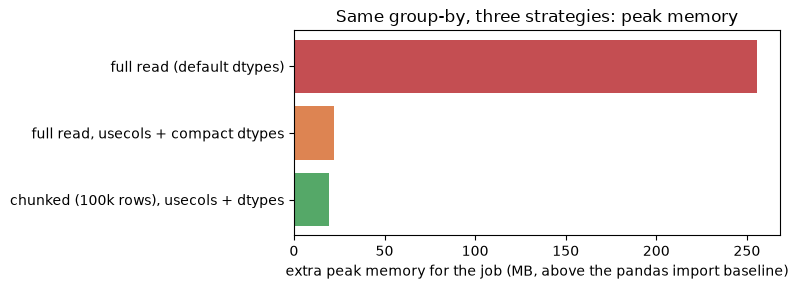

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(mem["strategy"], mem["extra for the job MB"], color=["#c44e52", "#dd8452", "#55a868"])
ax.set_xlabel("extra peak memory for the job (MB, above the pandas import baseline)")
ax.set_title("Same group-by, three strategies: peak memory")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**What just happened?** All three strategies produce the same total. Reading everything with default dtypes needs by far the most extra memory: eight columns, three of them strings stored as Python objects. Reading only the two needed columns with compact dtypes (`usecols`, `category`, `float32`) cuts the peak several-fold. Chunking lowers it a little further here and, more importantly, its peak **no longer grows with the file**: a 100 GB file would need about the same memory as this one, because only one 100,000-row chunk plus a tiny partial result is in RAM at a time.

| technique | what it saves | caveat |
|---|---|---|
| `usecols=` | columns you drop are never stored | every character of the CSV is still scanned, so it saves memory, not much time |
| `dtype=` (`int32`, `float32`, `category`) | 2–10× less memory per column | `float32` has about 7 significant digits; use `float64` for money sums or round at the end |
| `chunksize=` | memory independent of file size | only decomposable aggregations; sorting and joins need more care (Section 7) |
| a columnar format (next section) | skips columns *and* rows without parsing | needs a one-off conversion |

> ⚠️ **Common mistake:** `chunk.mean()` per chunk and then the mean of those means. Unless all chunks are the same size, that is wrong (Section 2.3). Keep `sum` and `count`.

---
## 4. Columnar storage: Parquet, row groups and partitioning

> 💬 **In plain English:** store data by column, in labelled folders, with a small summary at the end, so queries can skip most of it.

**Apache Parquet** is an open **columnar** file format. Instead of storing row 1, row 2, … (like CSV), it stores all values of column 1 together, then column 2, and so on. A file is split into **row groups** (horizontal slices, typically about 64 MB–1 GB, or a fixed number of rows); inside each row group every column is a **column chunk** made of compressed **pages**. The **footer** stores the schema plus **statistics** (min, max, null count) for every column chunk.

```
 events.parquet
 ┌──────────────────────── row group 0 (rows 0 .. 99,999) ─────────────────────┐
 │ [event_id chunk] [ts chunk] [day chunk] [user_id chunk] ... [amount chunk]   │
 ├──────────────────────── row group 1 (rows 100,000 .. 199,999) ──────────────┤
 │ [event_id chunk] [ts chunk] ...                                              │
 ├──────────────────────────────────────────────────────────────────────────────┤
 │ FOOTER: schema + per row group, per column: min, max, null_count, offsets   │
 └──────────────────────────────────────────────────────────────────────────────┘
```

This layout enables two big savings that every modern engine (Spark, DuckDB, Polars, BigQuery, Snowflake) uses:

- **Column pruning** (projection pushdown): read only the column chunks the query needs.
- **Predicate pushdown** (row-group skipping): if the footer says a row group's `ts` lies between Sept 1 and Sept 3, a query for Sept 20 skips it **without decompressing it**.

**Partitioning** goes one level up: write one folder per value of a low-cardinality column, e.g. `day=2026-09-20/part-0.parquet` (the "**Hive-style**" layout). A filter on `day` then skips whole files (**partition pruning**).

In [9]:
PQ_FILE = WORK / "events.parquet"
pq.write_table(events, PQ_FILE, row_group_size=100_000, compression="zstd")   # 10 row groups
meta = pq.ParquetFile(PQ_FILE).metadata
print(f"CSV {CSV.stat().st_size/1e6:.1f} MB  ->  Parquet {PQ_FILE.stat().st_size/1e6:.1f} MB "
      f"({meta.num_row_groups} row groups, {meta.num_columns} columns)")

# The footer: min/max statistics per row group for the 'ts' and 'user_id' columns.
col_idx = {meta.schema.column(i).name: i for i in range(meta.num_columns)}
stats_rows = []
for rg in range(meta.num_row_groups):
    ts_stats = meta.row_group(rg).column(col_idx["ts"]).statistics
    uid_stats = meta.row_group(rg).column(col_idx["user_id"]).statistics
    stats_rows.append({"row group": rg, "rows": meta.row_group(rg).num_rows,
                       "ts min": ts_stats.min, "ts max": ts_stats.max,
                       "user_id min": uid_stats.min, "user_id max": uid_stats.max})
footer = pd.DataFrame(stats_rows)
print(footer.head(4).to_string(index=False))

CSV 70.3 MB  ->  Parquet 9.5 MB (10 row groups, 8 columns)
 row group   rows              ts min              ts max  user_id min  user_id max
         0 100000 2026-09-01 00:00:02 2026-09-04 00:30:11            1       199984
         1 100000 2026-09-04 00:30:14 2026-09-07 00:34:06            1       199951
         2 100000 2026-09-07 00:34:08 2026-09-10 00:19:54            1       199814
         3 100000 2026-09-10 00:19:56 2026-09-13 00:28:22            1       199985


Because the data was written **sorted by time**, each row group covers a narrow, non-overlapping `ts` range, while `user_id` is spread over almost the whole range in every row group. Let us implement row-group skipping from scratch: for a predicate `lo <= column <= hi`, a row group can be skipped when `max < lo` or `min > hi`.

In [10]:
def row_groups_to_read(footer, col, lo, hi):
    # Row-group skipping from footer statistics: keep a group only if its [min, max] overlaps [lo, hi].
    keep = ~((footer[f"{col} max"] < lo) | (footer[f"{col} min"] > hi))
    return footer.loc[keep, "row group"].tolist()

lo, hi = pd.Timestamp("2026-09-20"), pd.Timestamp("2026-09-20 23:59:59")
by_ts = row_groups_to_read(footer, "ts", lo, hi)
by_uid = row_groups_to_read(footer, "user_id", 1000, 1010)
print("query on ts (one day):        read row groups", by_ts, f"-> skip {meta.num_row_groups - len(by_ts)} of {meta.num_row_groups}")
print("query on user_id in [1000,1010]: read row groups", by_uid, f"-> skip {meta.num_row_groups - len(by_uid)}")

# Check: PyArrow's reader with the same filter returns exactly the rows in those row groups that match.
tbl = pq.read_table(PQ_FILE, columns=["ts", "amount"], filters=[("ts", ">=", lo), ("ts", "<=", hi)])
manual = pq.ParquetFile(PQ_FILE).read_row_groups(by_ts, columns=["ts", "amount"]).to_pandas()
manual = manual[(manual.ts >= lo) & (manual.ts <= hi)]
assert len(manual) == tbl.num_rows and np.isclose(manual.amount.sum(), pc_sum := float(tbl.column("amount").to_numpy().sum()))
print(f"rows on 2026-09-20: {tbl.num_rows:,}, revenue {pc_sum:,.2f} (same via manual skipping)")

query on ts (one day):        read row groups [6] -> skip 9 of 10
query on user_id in [1000,1010]: read row groups [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] -> skip 0
rows on 2026-09-20: 33,326, revenue 80,419.47 (same via manual skipping)


**What just happened?** The one-day query needs only the row group(s) whose time range overlaps that day; the rest are skipped using a few bytes of footer. The `user_id` query cannot skip anything, because every row group contains small and large ids. **Statistics only help on columns the data is sorted or clustered by.** That is why table formats offer "sort by", "Z-order" or "liquid clustering" options: they reorganise data so more queries can skip more.

### 4.1 Partitioning by date, and measured speedups

We now write a Hive-partitioned dataset (one folder per day) and time the same query, "revenue per country on one day", five ways.

In [11]:
PART_DIR = WORK / "events_by_day"
ds.write_dataset(events, PART_DIR, format="parquet", partitioning=["day"], partitioning_flavor="hive",
                 max_rows_per_group=100_000)
day_dirs = sorted(p.name for p in PART_DIR.iterdir())
print(len(day_dirs), "partition folders, e.g.", day_dirs[:2], "...", f"total {folder_mb(PART_DIR):.1f} MB")
DAY = "2026-09-20"

def q_csv_full():                     # parse everything, then filter
    df = pd.read_csv(CSV)
    return df[df.day == DAY].groupby("country")["amount"].sum()

def q_csv_usecols():                  # parse 3 columns, then filter
    df = pd.read_csv(CSV, usecols=["day", "country", "amount"])
    return df[df.day == DAY].groupby("country")["amount"].sum()

def q_parquet_all_columns():          # columnar, but read every column of every row group
    df = pd.read_parquet(PQ_FILE)
    return df[df.day == DAY].groupby("country")["amount"].sum()

def q_parquet_pruned():               # column pruning + predicate pushdown via statistics
    df = pd.read_parquet(PQ_FILE, columns=["country", "amount"], filters=[("day", "==", DAY)])
    return df.groupby("country")["amount"].sum()

def q_partitioned():                  # partition pruning: open only the day=2026-09-20 folder
    dset = ds.dataset(PART_DIR, format="parquet", partitioning="hive")
    df = dset.to_table(columns=["country", "amount"], filter=ds.field("day") == DAY).to_pandas()
    return df.groupby("country")["amount"].sum()

speed = []
answers = {}
for name, fn in [("CSV, all columns", q_csv_full), ("CSV, usecols", q_csv_usecols),
                 ("Parquet, all columns", q_parquet_all_columns), ("Parquet, columns + filter", q_parquet_pruned),
                 ("partitioned Parquet", q_partitioned)]:
    answers[name], secs = timed(fn, repeat=1 if name.startswith("CSV") else 3)
    speed.append({"method": name, "seconds": secs})
speed = pd.DataFrame(speed)
speed["speedup vs CSV"] = (speed.seconds.iloc[0] / speed.seconds).round(1)
ref = answers["CSV, all columns"]
for k, v in answers.items():
    assert np.allclose(v.sort_index().values, ref.sort_index().values), k
print(speed.round(4).to_string(index=False))
print("\nall five give the same revenue per country, e.g. PK =", round(ref["PK"], 2))

30 partition folders, e.g. ['day=2026-09-01', 'day=2026-09-02'] ... total 15.3 MB


                   method  seconds  speedup vs CSV
         CSV, all columns   3.1210             1.0
             CSV, usecols   1.2744             2.4
     Parquet, all columns   0.4287             7.3
Parquet, columns + filter   0.0184           169.2
      partitioned Parquet   0.0108           288.5

all five give the same revenue per country, e.g. PK = 20369.72


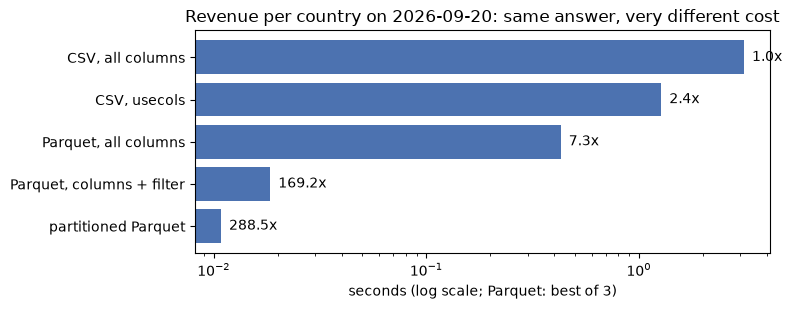

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(speed["method"], speed["seconds"], color="#4c72b0")
for i, (s, x) in enumerate(zip(speed["seconds"], speed["speedup vs CSV"])):
    ax.text(s, i, f"  {x}x", va="center")
ax.set_xscale("log"); ax.invert_yaxis()
ax.set_xlabel("seconds (log scale; Parquet: best of 3)"); ax.set_title(f"Revenue per country on {DAY}: same answer, very different cost")
plt.tight_layout(); plt.show()

**What just happened?** Every method gives the same numbers, but the cost differs by one to two orders of magnitude (exact timings vary with machine load; the ordering is what matters). CSV must be parsed character by character even for columns we drop, so `usecols` saves memory but almost no time. Parquet is already binary and typed, and with column pruning plus a filter it touches only a small part of the file. The partitioned dataset opens exactly one folder of 30. On a cloud data lake, where you pay per byte scanned (BigQuery, Athena), the same ordering is also a **cost** ordering.

> ⚠️ **Common mistake:** partitioning by a **high-cardinality** column such as `user_id`. You get hundreds of thousands of tiny files, and listing and opening them costs more than the data itself (the "small-files problem", measured in [notebook 03](03_spark_locally.ipynb)). Partition by low-cardinality columns that queries filter on (date, region), and aim for files of roughly 100 MB to 1 GB.

---
## 5. DuckDB (and Polars) on data larger than the memory limit

> 💬 **In plain English:** let a query engine stream the data and, if memory runs out, park the overflow on disk.

Instead of you writing the chunk loop, a **query engine** can do it. DuckDB and Polars read Parquet in a **streaming** fashion: data flows through the operators (scan → filter → aggregate) in batches of a few thousand rows ("vectors" in DuckDB, "morsels" in Polars), so a whole column never has to be in memory. When an operator such as a sort, join or large group-by truly needs more memory than allowed, DuckDB **spills** intermediate data to temporary files on disk and carries on, instead of crashing.

First, the query plan: DuckDB's `EXPLAIN` shows the pushdowns we did by hand in Section 4.

In [13]:
con = duckdb.connect()                                   # in-memory database, nothing written to the repo
con.execute("SET enable_progress_bar = false")          # no progress-bar widgets in the saved notebook
con.execute("SET threads = 2")                           # modest on a shared machine
glob = str(PART_DIR / "**" / "*.parquet")
plan = con.execute(f'''
    EXPLAIN
    SELECT country, SUM(amount) AS revenue
    FROM read_parquet('{glob}', hive_partitioning = true)
    WHERE day = '{DAY}'
    GROUP BY country
''').fetchall()[0][1]
print(plan)
duck = con.execute(f'''SELECT country, SUM(amount) AS revenue FROM read_parquet('{glob}', hive_partitioning = true)
                       WHERE day = '{DAY}' GROUP BY country ORDER BY country''').df().set_index("country")["revenue"]
assert np.allclose(duck.values, ref.sort_index().values)
print("DuckDB result matches pandas.")

┌───────────────────────────┐
│       HASH_GROUP_BY       │
│    ────────────────────   │
│         Groups: #0        │
│    Aggregates: sum(#1)    │
│                           │
│        ~21,014 rows       │
└─────────────┬─────────────┘
┌─────────────┴─────────────┐
│         PROJECTION        │
│    ────────────────────   │
│          country          │
│           amount          │
│                           │
│        ~33,245 rows       │
└─────────────┬─────────────┘
┌─────────────┴─────────────┐
│        READ_PARQUET       │
│    ────────────────────   │
│         Function:         │
│        READ_PARQUET       │
│                           │
│        Projections:       │
│          country          │
│           amount          │
│                           │
│       File Filters:       │
│ (day = '2026-09-20'::DATE)│
│                           │
│    Scanning Files: 1/30   │
│                           │
│        ~33,245 rows       │
└───────────────────────────┘

DuckDB re

**What just happened?** Read the plan from the bottom up. The `READ_PARQUET` operator lists only the two **Projections** the query needs (`country`, `amount`), applies the `day` filter as a **file filter**, and reports that it scans only **1 of the 30 files**. That is column pruning, predicate pushdown and partition pruning, chosen automatically by the optimiser (the same ideas as in [DBMS 08: query processing](../00_dbms_fundamentals/08_query_processing_and_optimization.ipynb)).

### 5.1 Spilling: a sort bigger than the memory limit

We give DuckDB a deliberately tiny memory limit, ask it to **sort** 2 million rows with random 32-character strings (roughly 130 MB of data in memory), and watch its temporary folder while the query runs.

In [14]:
import threading

SPILL = WORK / "duckdb_spill"
def sort_with_limit(limit):
    c = duckdb.connect()
    c.execute("SET enable_progress_bar = false")
    c.execute(f"SET memory_limit = '{limit}'")           # cap DuckDB's buffer memory
    c.execute(f"SET temp_directory = '{SPILL}'")         # where it may spill
    c.execute("SET threads = 2")
    c.execute("SET preserve_insertion_order = false")   # lets streaming operators use less memory
    src = WORK / "big_unsorted.parquet"
    if not src.exists():
        c.execute(f'''COPY (SELECT i AS id, md5(i::VARCHAR) AS key, random() AS value
                           FROM range(2000000) r(i)) TO '{src}' ''')
    peak = [0]; done = threading.Event()
    def watch():                                         # sample the spill folder size every 5 ms
        while not done.is_set():
            peak[0] = max(peak[0], sum(f.stat().st_size for f in SPILL.rglob("*") if f.is_file()) if SPILL.exists() else 0)
            time.sleep(0.005)
    th = threading.Thread(target=watch, daemon=True); th.start()
    try:
        t0 = time.perf_counter()
        c.execute(f"COPY (SELECT * FROM '{src}' ORDER BY key) TO '{WORK / 'big_sorted.parquet'}'")
        secs = time.perf_counter() - t0
    finally:
        done.set(); th.join(); c.close()
    first = con.sql(f"SELECT key FROM '{WORK / 'big_sorted.parquet'}' LIMIT 3").fetchall()
    return secs, peak[0] / 1e6, first

spill_rows = []
for limit in ["2GB", "100MB"]:
    secs, peak_mb, first = sort_with_limit(limit)
    spill_rows.append({"memory_limit": limit, "seconds": round(secs, 2), "peak spill on disk (MB)": round(peak_mb, 1)})
print(pd.DataFrame(spill_rows).to_string(index=False))
print("input size:", round((WORK / "big_unsorted.parquet").stat().st_size / 1e6, 1), "MB compressed; first sorted keys:", [k[0][:8] for k in first])
check = con.sql(f"SELECT bool_and(key >= prev) FROM (SELECT key, lag(key) OVER () AS prev FROM '{WORK / 'big_sorted.parquet'}') WHERE prev IS NOT NULL").fetchone()[0]
assert check, "output is not sorted"
print("output verified sorted")

memory_limit  seconds  peak spill on disk (MB)
         2GB     1.54                      0.0
       100MB     3.22                    119.2
input size: 89.2 MB compressed; first sorted keys: ['00000f72', '0000104c', '0000180e']


output verified sorted


**What just happened?** With 2 GB of memory the sort runs entirely in RAM and the spill folder stays empty. With a 100 MB limit (less than the data), DuckDB writes sorted runs to disk, then merges them: the spill folder briefly holds about as much data as the whole input (see the table), the query is slower because of the extra disk writes and reads, and the result is still correct. That is the **external merge sort** of Section 7, done for you by the engine. Without spilling, a pandas `sort_values` on data larger than RAM simply fails with `MemoryError` (or the operating system kills the process).

### 5.2 Polars lazy queries (optional)

Polars' **lazy API** builds a query plan first (`scan_parquet` instead of `read_parquet`) and optimises it before running; `collect(engine="streaming")` executes it in batches. If Polars is not installed, the cell is skipped and the DuckDB result above is the reference.

In [15]:
if HAS_POLARS:
    import polars as pl
    lazy = (pl.scan_parquet(str(PQ_FILE))                      # nothing is read yet
              .filter(pl.col("day") == DAY)
              .group_by("country").agg(pl.col("amount").sum().alias("revenue"))
              .sort("country"))
    print(lazy.explain())                                     # optimised plan: note the pushed-down filter and projection
    try:
        out = lazy.collect(engine="streaming")                # recent Polars 1.x
    except TypeError:
        out = lazy.collect(streaming=True)                    # older Polars
    assert np.allclose(out["revenue"].to_numpy(), ref.sort_index().values)
    print(out)
else:
    print("⏭️ Polars is not installed: skipped (optional; `pip install polars` to try it). DuckDB above shows the same plan ideas.")

⏭️ Polars is not installed: skipped (optional; `pip install polars` to try it). DuckDB above shows the same plan ideas.


---
## 6. Data skew, partition sizing and salting

> 💬 **In plain English:** a parallel job is only as fast as its slowest worker, and one very popular key can make one worker do most of the work.

**Data skew** means some keys have far more records than others. Real data is almost always skewed (Zipf-like): a few users, products or words dominate. In a shuffle, all records of a key go to **one** partition, so the partition holding the hottest key becomes a **straggler** and the whole stage waits for it.

A standard fix for aggregations is **salting**: append a random "salt" $s \in \{0, \dots, k-1\}$ to hot keys, aggregate by `(key, salt)` in a first stage (the hot key's work is now spread over $k$ partitions), then aggregate again by `key` alone (now at most $k$ partial results per key).

hottest user 1 has 50,659 of 200,000 rows (25.3%)
max/mean partition size  before salting: 2.46  after salting: 1.02


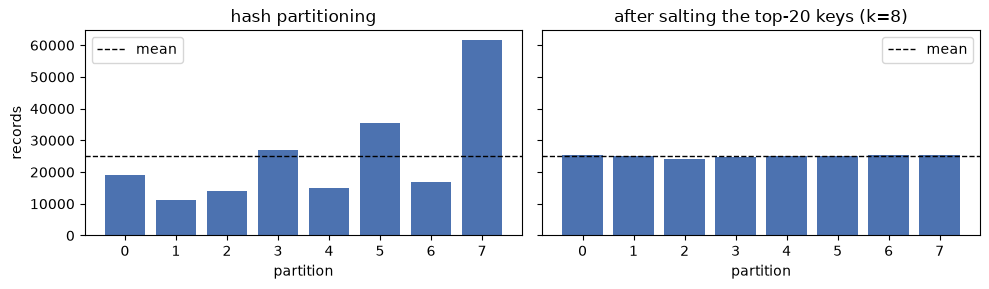

In [16]:
user_keys = events.column("user_id").to_numpy()
P = 8                                                            # number of shuffle partitions

def partition_sizes(keys, n_parts):
    # Hash-partition integer keys and return the number of records per partition.
    part = np.array([zlib.crc32(str(k).encode()) % n_parts for k in keys])
    return np.bincount(part, minlength=n_parts)

sample = user_keys[:200_000]                                     # a 200k-row sample is enough to see the shape
before = partition_sizes(sample, P)
top_key, top_count = Counter(sample.tolist()).most_common(1)[0]

# Salting: the hottest keys get a salt 0..k-1, so their rows spread over up to k partitions.
k = 8
hot = {key for key, c in Counter(sample.tolist()).most_common(20)}
salt = RNG.integers(0, k, len(sample))
salted_keys = [f"{u}#{s}" if u in hot else str(u) for u, s in zip(sample.tolist(), salt)]
after = partition_sizes(salted_keys, P)

# Two-stage aggregation with salting gives the same counts as the direct group-by.
stage1 = Counter(salted_keys)                                    # count per (key, salt)
stage2 = Counter()
for sk, c in stage1.items():
    stage2[int(sk.split("#")[0])] += c                           # drop the salt and add up
assert stage2 == Counter(sample.tolist())

print(f"hottest user {top_key} has {top_count:,} of {len(sample):,} rows ({top_count/len(sample):.1%})")
print("max/mean partition size  before salting:", round(before.max() / before.mean(), 2),
      " after salting:", round(after.max() / after.mean(), 2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, sizes, title in [(axes[0], before, "hash partitioning"), (axes[1], after, f"after salting the top-20 keys (k={k})")]:
    ax.bar(range(P), sizes, color="#4c72b0"); ax.axhline(sizes.mean(), color="k", ls="--", lw=1, label="mean")
    ax.set_xlabel("partition"); ax.set_title(title); ax.legend()
axes[0].set_ylabel("records")
plt.tight_layout(); plt.show()

**What just happened?** Because `user_id` is Zipf-distributed, one user owns a large share of all rows, so one partition is far bigger than the mean (the max/mean ratio printed above). The stage's run time is set by that partition. After salting the 20 hottest keys, their rows are spread over several partitions, the bars even out and the max/mean ratio drops towards 1. The two-stage aggregation gives exactly the same counts as a direct `Counter`.

**Choosing the number of partitions.** A common rule: aim for partitions of roughly **100–200 MB** (Spark's default input split is 128 MB) and at least **2–4 partitions per CPU core**, so that work can be balanced. Too few partitions: idle cores and huge, spilling tasks. Too many: scheduling overhead and tiny files.

In [17]:
def suggest_partitions(total_bytes, cores, target_mb=128):
    # Enough partitions to keep each near target_mb, and at least 2 per core for load balancing.
    by_size = int(np.ceil(total_bytes / (target_mb * 1e6)))
    return max(by_size, 2 * cores)

for size_gb, cores in [(0.05, 8), (10, 8), (500, 64)]:
    print(f"{size_gb:>6} GB on {cores:>2} cores -> {suggest_partitions(size_gb * 1e9, cores):>5} partitions")

  0.05 GB on  8 cores ->    16 partitions
    10 GB on  8 cores ->    79 partitions
   500 GB on 64 cores ->  3907 partitions


> 🎓 **Exam / interview tip:** "One task in my Spark job takes 30 minutes while the others take 30 seconds. Why?" Answer: data skew on the shuffle key. Fixes, in order: filter or pre-aggregate the hot keys, broadcast the small side of a join (no shuffle at all), salting, and Spark's **adaptive query execution** (AQE, on by default since Spark 3.2), which can split skewed join partitions automatically. Notebook 03 implements broadcast joins and salted joins.

---
## 7. External merge sort: sorting more data than fits in memory

> 💬 **In plain English:** sort the data in pieces that fit in memory, save each sorted piece, then merge the pieces like zipping sorted card piles together.

The **external merge sort** is the classic external-memory algorithm, used by every database for `ORDER BY`, sort-merge joins and index builds (and by DuckDB in Section 5.1):

1. **Run generation:** read $M$ records (what fits in memory), sort them, write them out as a sorted **run**. This gives $\lceil N/M \rceil$ runs.
2. **$k$-way merge:** open all runs and repeatedly output the smallest head element, using a **min-heap** of size $k$ (one entry per run).

With $N$ records, memory $M$ and block size $B$ (records per disk block), the I/O cost is $O\!\left(\frac{N}{B} \log_{M/B} \frac{N}{B}\right)$ block transfers; when the number of runs is at most $M/B$, one merge pass suffices and the whole sort reads and writes the data **twice**. A full treatment with measured I/O counts is in [advanced algorithms 10: parallel and external-memory algorithms](../../00_AI_Fundamentals/advanced_algorithms/10_parallel_and_external_memory_algorithms.ipynb).

In [18]:
def external_sort(in_path, out_path, mem_records, tmp_dir):
    # Sort a file of one integer per line using at most `mem_records` integers in memory at once.
    runs = []
    with open(in_path) as f:
        while True:
            chunk = [int(x) for _, x in zip(range(mem_records), f)]   # read at most M lines
            if not chunk:
                break
            chunk.sort()                                               # in-memory sort of one run
            run = Path(tmp_dir) / f"run_{len(runs):04d}.txt"
            run.write_text("\n".join(map(str, chunk)) + "\n")
            runs.append(run)
    files = [open(r) for r in runs]
    try:
        streams = [(int(line) for line in fh) for fh in files]          # lazy readers, one per run
        with open(out_path, "w") as out:
            for value in heapq.merge(*streams):                         # k-way merge with a heap
                out.write(f"{value}\n")
    finally:
        for fh in files:
            fh.close()
    return len(runs)

ints = RNG.integers(0, 10**9, 300_000)
src, dst = WORK / "ints.txt", WORK / "ints_sorted.txt"
src.write_text("\n".join(map(str, ints)) + "\n")
run_dir = WORK / "runs"; run_dir.mkdir()
n_runs, secs = timed(external_sort, src, dst, 25_000, run_dir)
result = np.loadtxt(dst, dtype=np.int64)
assert np.array_equal(result, np.sort(ints))
print(f"sorted {len(ints):,} integers with memory for 25,000 -> {n_runs} runs, one 12-way merge, {secs:.2f} s; matches np.sort")

sorted 300,000 integers with memory for 25,000 -> 12 runs, one 12-way merge, 0.88 s; matches np.sort


**What just happened?** The 300,000 integers never had to be in memory together: 12 sorted runs of 25,000 were written, and `heapq.merge` combined them, holding only one value per run in its heap. The output equals `np.sort`. The heap merge costs $O(N \log k)$ comparisons for $k$ runs.

---
## 8. Task graphs: a mini-Dask, and real Dask (optional)

> 💬 **In plain English:** write down every small job and what it waits for, then run ready jobs in parallel.

> 💬 **In plain English:** write down every small job and which jobs it waits for, then run all jobs whose inputs are ready, in parallel.

**Dask** splits a big DataFrame into many pandas DataFrames ("partitions") and turns your code into a **task graph**: a directed acyclic graph (DAG) where each node is a small Python function call on one partition and edges are data dependencies. Nothing runs until you call `.compute()`; then a **scheduler** runs tasks whose inputs are ready, in parallel, and frees intermediate results as soon as nobody needs them. Spark's DAG of stages (notebook 03) is the same idea.

We build the graph for our query by hand and run it with a tiny scheduler: one `read → filter → partial aggregate` chain per day partition, and one final `combine` task.

mini-Dask result matches pandas:
 country
BR    50.98
DE    50.75
GB    50.82
ID    48.95
IN    49.41
NG    49.51
PK    50.32
US    50.23
first 8 tasks completed: ['read-01', 'read-02', 'read-03', 'read-04', 'read-05', 'read-06', 'read-07', 'read-08']


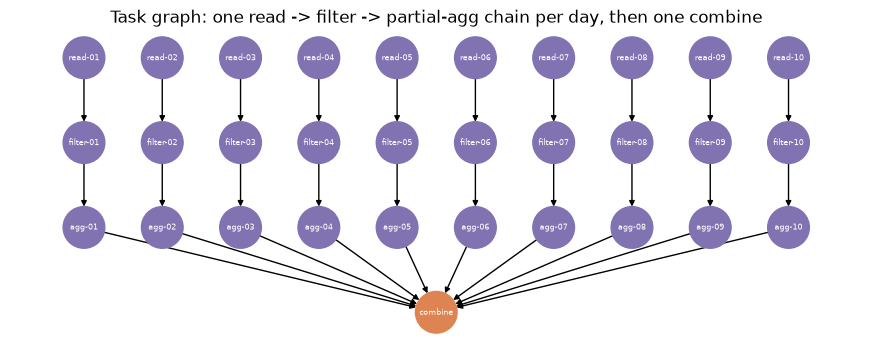

In [19]:
import networkx as nx
from concurrent.futures import ThreadPoolExecutor

def read_part(day):                   # task: read one partition (one day folder)
    return pd.read_parquet(PART_DIR / f"day={day}", columns=["country", "amount", "event_type"])
def only_buys(df):                    # task: filter
    return df[df.event_type == "buy"]
def partial_sum(df):                  # task: partial aggregate (a combiner!)
    return df.groupby("country")["amount"].agg(["sum", "count"])
def combine(*parts):                  # task: final aggregate over all partials
    tot = pd.concat(parts).groupby(level=0).sum()
    return (tot["sum"] / tot["count"]).rename("avg_basket")

graph = {}                            # task name -> (function, [names of input tasks] or a literal argument)
days = day_dirs[:10]                  # first 10 days keep the picture readable
for d in days:
    day = d.split("=")[1]
    graph[f"read-{day[-2:]}"] = (read_part, day)
    graph[f"filter-{day[-2:]}"] = (only_buys, [f"read-{day[-2:]}"])
    graph[f"agg-{day[-2:]}"] = (partial_sum, [f"filter-{day[-2:]}"])
graph["combine"] = (combine, [f"agg-{d.split('=')[1][-2:]}" for d in days])

def run_graph(graph, workers=2):
    # A tiny dynamic scheduler: submit every task whose inputs are done; free results nobody needs.
    deps = {t: (a if isinstance(a, list) else []) for t, (_, a) in graph.items()}
    users = Counter(d for ds_ in deps.values() for d in ds_)            # how many tasks consume each result
    done, running, order = {}, {}, []
    with ThreadPoolExecutor(workers) as ex:
        while len(order) < len(graph):
            for t, (fn, arg) in graph.items():                            # launch ready tasks
                if t not in done and t not in running and all(d in done for d in deps[t]):
                    args = [done[d] for d in deps[t]] if deps[t] else [arg]
                    running[t] = ex.submit(fn, *args)
            t = next(t for t, fut in running.items() if fut.done()) if any(f.done() for f in running.values()) else None
            if t is None:
                time.sleep(0.001); continue
            done[t] = running.pop(t).result(); order.append(t)
            for d in deps[t]:                                             # release memory early
                users[d] -= 1
                if users[d] == 0 and d in done:
                    done[d] = None
    return done, order

done, order = run_graph(graph)
ev = events.select(["day", "country", "event_type", "amount"]).to_pandas()
ev = ev[(ev.event_type == "buy") & ev.day.isin([d.split("=")[1] for d in days])]
expected = ev.groupby("country")["amount"].mean()
assert np.allclose(done["combine"].sort_index().values, expected.sort_index().values)
print("mini-Dask result matches pandas:\n", done["combine"].round(2).to_string())
print("first 8 tasks completed:", order[:8])

G = nx.DiGraph([(d, t) for t, (_, a) in graph.items() if isinstance(a, list) for d in a])
pos = {}
for i, d in enumerate(days):
    s = d.split("=")[1][-2:]
    for layer, name in enumerate(["read", "filter", "agg"]):
        pos[f"{name}-{s}"] = (i, -layer)
pos["combine"] = ((len(days) - 1) / 2, -3)
plt.figure(figsize=(11, 4))
nx.draw_networkx(G, pos, node_color=["#dd8452" if n == "combine" else "#8172b2" for n in G.nodes],
                 node_size=900, font_size=6, font_color="white", arrowsize=8)
plt.title("Task graph: one read -> filter -> partial-agg chain per day, then one combine"); plt.axis("off"); plt.show()

**What just happened?** The graph has 31 tasks: three per day plus one combine. The scheduler ran ready tasks two at a time and freed each intermediate result as soon as its consumer finished. The result equals plain pandas. Notice the completion order: our naive scheduler starts every ready `read` task first, so all ten days can be in memory at once before any filter runs. Real schedulers such as Dask's prefer to **finish one chain before starting the next** (depth-first ordering), precisely so that intermediate data can be freed early and memory stays at a few partitions. Dask adds much more: work stealing between workers, spilling to disk and a distributed mode.

The real Dask version of the same pipeline (skipped if Dask is not installed):

In [20]:
if HAS_DASK:
    import dask
    import dask.dataframe as dd
    ddf = dd.read_parquet(str(PART_DIR), columns=["country", "amount", "event_type", "day"])
    ddf = ddf[ddf.day.isin([d.split("=")[1] for d in days]) & (ddf.event_type == "buy")]
    lazy_avg = ddf.groupby("country")["amount"].mean()        # still lazy: just a graph
    print("partitions:", ddf.npartitions, "| tasks in graph:", len(lazy_avg.__dask_graph__()))
    with dask.config.set(scheduler="threads", num_workers=2):
        dask_avg = lazy_avg.compute()
    assert np.allclose(dask_avg.sort_index().values, expected.sort_index().values)
    print(dask_avg.round(2))
    # lazy_avg.visualize("graph.png") draws the task graph, but it needs the graphviz program.
else:
    print("⏭️ Dask is not installed: skipped (optional; `pip install \"dask[dataframe]\"`). The mini-Dask above is the same idea.")

⏭️ Dask is not installed: skipped (optional; `pip install "dask[dataframe]"`). The mini-Dask above is the same idea.


---
## 9. Choosing a tool: pandas, Polars, DuckDB, Dask, Spark

> 💬 **In plain English:** use the simplest tool that fits your data; move up only when you hit a real limit.

| | pandas | Polars | DuckDB | Dask | Spark |
|---|---|---|---|---|---|
| model | eager DataFrame | eager + **lazy** DataFrame | SQL engine (in-process) | lazy pandas-like, task graph | lazy DataFrame / SQL, DAG of stages |
| parallelism | 1 core (mostly) | all cores | all cores | cores or a cluster | a cluster (or `local[*]`) |
| larger than RAM? | only with manual chunks | yes, streaming engine | yes, streaming + spilling | yes, partitions + spilling | yes, partitions + spilling |
| sweet spot | < ~1–5 GB, interactive | 1–100+ GB on one machine | 1 GB–TB on one machine, SQL | scale existing pandas/NumPy code | TB–PB, many machines, mature ecosystem |
| set-up cost | none | `pip install polars` | `pip install duckdb` | `pip install dask` (+ cluster) | JVM, cluster manager (or managed: Databricks, EMR, Dataproc) |
| watch out for | copies, `object` strings | different API from pandas | single-node only | many tiny tasks, Python overhead | shuffle cost, JVM tuning, small files |

**When to move up:** pandas → Polars/DuckDB when data stops fitting comfortably in RAM or queries get slow (often the only step you need: one modern machine with 64–512 GB RAM and fast SSDs handles a lot). → Dask when you have a large existing pandas/NumPy code base to scale out. → Spark (or a cloud warehouse such as BigQuery or Snowflake) when data is many terabytes, lives in a data lake shared by many teams, or a single machine cannot finish in time.

---
## 10. 🔗 How this connects to modern AI

> 💬 **In plain English:** these exact patterns prepare the data behind every large AI model.

- **LLM pre-training data.** Web-scale corpora (Common Crawl snapshots are hundreds of terabytes) are filtered, deduplicated and tokenised with exactly these patterns: MapReduce-style jobs on Spark, Ray or libraries such as Hugging Face's `datatrove`, word/token counts with combiners, MinHash dedup ([advanced algorithms 06](../../00_AI_Fundamentals/advanced_algorithms/06_streaming_and_sketching_algorithms.ipynb)) and Parquet shards partitioned by language or source.
- **Datasets for training.** Hugging Face `datasets` stores data as **Apache Arrow** tables memory-mapped from disk, so a dataset much larger than RAM can be shuffled and batched; the Hub serves many datasets as Parquet. PyTorch `DataLoader` workers are the "map tasks" of training ([PyTorch training pipeline](../../05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb), [distributed training](../../05_Deep_Learning/11_distributed_training.ipynb)).
- **Feature engineering at scale.** Point-in-time features for ML models are computed by partitioned group-bys and joins over event tables in a data lake, then served from a feature store ([feature stores](../../15_MLOps/12_feature_stores.ipynb), [SQL for ML features](../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb)). Skew on popular users/items is a daily problem there.
- **Embeddings and RAG.** Embedding millions of documents is an embarrassingly parallel map job; the inverted index of Section 2.3 is the keyword (BM25) half of hybrid retrieval ([RAG](../../08_LLM/02_rag/01_rag_fundamentals.ipynb)).
- **Evaluation and monitoring logs.** LLM request logs are written as partitioned Parquet (by day, model version) and queried with DuckDB or a warehouse; partition pruning keeps dashboards cheap ([monitoring](../../15_MLOps/06_monitoring/01_monitoring.ipynb)).

---
## 11. Recap

- "Big" is relative: estimate **rows × bytes per row**, compare with RAM, and estimate one pass as size ÷ bandwidth. Strings stored as Python objects are the usual memory hog; categoricals and compact dtypes fix much of it.
- **MapReduce** = map → **shuffle** (partition by a stable hash of the key, group) → reduce. Word count, inverted indexes, joins and group-bys are all a few lines. **Combiners** shrink the shuffle but only for distributive/algebraic aggregates (keep `(sum, count)`, never average averages).
- **Out-of-core pandas**: `usecols` + compact `dtype` + `chunksize` give a peak memory that does not grow with the file.
- **Parquet** is columnar with row groups and min/max statistics: **column pruning**, **predicate pushdown** and Hive-style **partition pruning** make queries one to two orders of magnitude cheaper than CSV. Statistics only help on sorted/clustered columns.
- **DuckDB/Polars** do the chunking for you with streaming execution, and DuckDB **spills** to disk when a sort or join exceeds the memory limit.
- **Skew** makes one partition a straggler; fix it with pre-aggregation, broadcast joins, **salting** or AQE. Size partitions around 100–200 MB with at least 2–4 per core.
- **External merge sort** (sorted runs + $k$-way heap merge) is how every engine sorts data larger than memory.
- **Dask/Spark** build a lazy **task graph (DAG)** and a scheduler runs it in parallel; start with the simplest tool and move up only when needed.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy, conceptual)** A table has 400 million rows with columns `user_id` (int64), `price` (float64), `ts` (int64) and `city` (an `object` string of about 8 characters, 300 distinct values). Estimate its pandas memory with `city` as `object` and as `category`.

<details><summary>Show solution</summary>

Numeric columns: $3 \times 8 = 24$ bytes per row. `object` string (Python 3.12+): $8 + 41 + 8 = 57$ bytes per row. Total $\approx 81 \times 4\times10^8 \approx 32.4$ GB. As a category with 300 values the codes need `int16` (more than 127 categories), so 2 bytes per row: $26 \times 4\times10^8 \approx 10.4$ GB (plus a negligible 300-entry dictionary). Using the `estimate_bytes` helper: `estimate_bytes(4e8, {"user_id":"int64","price":"float64","ts":"int64","city":"str8"})` gives $3.24\times10^{10}$.

</details>

**2. (Easy, conceptual)** Which of these aggregations can use a MapReduce combiner directly, and what partial state would you send for each: sum, maximum, mean, variance, median, number of distinct users?

<details><summary>Show solution</summary>

- sum, max: yes, send the partial sum / max (distributive).
- mean: yes with state `(sum, count)` (algebraic).
- variance: yes with state `(count, sum, sum of squares)`; or, more numerically stable, `(count, mean, M2)` merged with Chan et al.'s parallel formula.
- median: no fixed-size exact state (holistic); send all values, or use an approximate quantile sketch (KLL, t-digest).
- distinct users: no fixed-size exact state; send the set of ids (exact but large) or a HyperLogLog sketch (approximate, a few KB, mergeable by register-wise max).

</details>

**3. (Medium, coding)** Write `max_map` / `max_reduce` functions for `minimr.run_mapreduce` that compute the **largest order amount per country** from `(country, amount)` rows, with a combiner. Check against pandas.

<details><summary>Show solution</summary>

```python
def max_map(row):
    country, amount = row
    yield country, amount

def max_reduce(country, amounts):          # max is associative + commutative -> also the combiner
    yield country, max(amounts)

out, stats = minimr.run_mapreduce([rows[i::4] for i in range(4)], max_map, max_reduce, combiner=max_reduce)
assert dict(out) == pd_join.groupby("country")["amount"].max().to_dict()
```

(Without a process pool the functions can live in the notebook; to use `pool=`, put them in a module as in Section 2.1.)

</details>

**4. (Medium, conceptual)** A Parquet file of orders is written **sorted by `order_date`**, with 50 row groups. Query A filters `order_date = '2026-09-15'`; query B filters `customer_id = 42`. Which query benefits from row-group statistics, and what could you change so that the other one benefits too?

<details><summary>Show solution</summary>

Query A: each row group covers a narrow date range, so the min/max statistics let the reader skip all but one or two row groups. Query B: every row group contains a wide range of customer ids, so nothing can be skipped. To help B, either sort (cluster) the data by `customer_id` within each date partition (partition by date, sort by customer inside), use a multi-dimensional clustering such as Z-order on `(order_date, customer_id)`, or add **Bloom filters** on `customer_id` (Parquet supports per-column-chunk Bloom filters, which answer "definitely not here" for point lookups).

</details>

**5. (Medium, coding)** Compute the **standard deviation of `amount` per country for buy events only**, reading `events.csv` in chunks of 100,000 rows, keeping only `(count, sum, sum of squares)` per country. Check against pandas (`ddof=1`).

<details><summary>Show solution</summary>

```python
acc = None
for chunk in pd.read_csv(CSV, usecols=["country", "event_type", "amount"], chunksize=100_000):
    b = chunk[chunk.event_type == "buy"]
    part = b.groupby("country")["amount"].agg(n="count", s="sum", ss=lambda x: (x ** 2).sum())
    acc = part if acc is None else acc.add(part, fill_value=0)
var = (acc.ss - acc.s ** 2 / acc.n) / (acc.n - 1)          # sample variance from the three sums
std_chunked = np.sqrt(var)
full = pd.read_csv(CSV, usecols=["country", "event_type", "amount"])
std_pandas = full[full.event_type == "buy"].groupby("country")["amount"].std()
assert np.allclose(std_chunked.sort_index(), std_pandas.sort_index())
```

For very large values or tiny variances, `sum of squares` loses precision; production code merges `(n, mean, M2)` with Welford/Chan updates instead.

</details>

**6. (Medium, conceptual)** One key holds 40% of 100 million records, and you hash-partition into 200 partitions. Roughly how many records does the biggest partition hold, and how does that change if you salt that key with $k = 50$ salts?

<details><summary>Show solution</summary>

Without salting, the hot key alone puts $0.4 \times 10^8 = 4\times10^7$ records in one partition, against an average of $10^8/200 = 5\times10^5$: about **80×** the mean, so that one task takes about 80 times longer than a typical one. With 50 salts the hot key's records are spread over (up to) 50 partitions, about $8\times10^5$ each, plus that partition's normal share of other keys ($\approx 0.6\times10^8/200 = 3\times10^5$), so the biggest partition is about $1.1\times10^6$, roughly **2×** the mean. The cost is a second, small aggregation stage (at most 50 partial results for that key).

</details>

**7. (Hard, coding)** Using a memory budget of `M` integers, how many runs and merge passes does an external sort of `N` integers need if the merge can only have a fan-in of `F` runs at a time? Write `passes(N, M, F)` and check `passes(300_000, 25_000, 12) == 1` and `passes(10**9, 10**6, 100) == 2`.

<details><summary>Show solution</summary>

```python
import math
def passes(N, M, F):
    runs = math.ceil(N / M)                      # run generation
    p = 0
    while runs > 1:
        runs = math.ceil(runs / F)               # each pass merges groups of F runs
        p += 1
    return p

assert passes(300_000, 25_000, 12) == 1          # 12 runs, one 12-way merge
assert passes(10**9, 10**6, 100) == 2            # 1000 runs -> 10 -> 1
```

So the number of merge passes is $\lceil \log_F \lceil N/M \rceil \rceil$, and each pass reads and writes all the data once.

</details>

## Further reading (additional learning resources)

- Dean & Ghemawat, "MapReduce: Simplified Data Processing on Large Clusters", OSDI 2004.
- Leskovec, Rajaraman & Ullman, *Mining of Massive Datasets* (3rd ed.), ch. 2 (MapReduce, combiners, joins, cost model): free at http://www.mmds.org
- Kleppmann, *Designing Data-Intensive Applications* (O'Reilly), ch. 3 (column-oriented storage) and ch. 10 (batch processing, MapReduce, joins, skew).
- Silberschatz, Korth & Sudarshan, *Database System Concepts* (7th ed.), ch. 15 (external sort-merge) and ch. 22 (parallel and distributed query processing).
- Apache Parquet documentation: https://parquet.apache.org/docs/ ; DuckDB "Tuning workloads" and "Out-of-core processing" guides: https://duckdb.org/docs/stable/guides/performance/how_to_tune_workloads
- GeeksforGeeks: [MapReduce architecture](https://www.geeksforgeeks.org/mapreduce-architecture/), [External sorting](https://www.geeksforgeeks.org/external-sorting/).

## Next notebook
➡️ [03 · Spark locally](03_spark_locally.ipynb): drivers, executors, lazy DAGs, shuffles, broadcast vs sort-merge joins, partitioned Parquet, MLlib and Structured Streaming, with a pure-Python fallback when PySpark is not installed.

In [21]:
# Clean up everything this notebook wrote.
con.close()
sys.path.remove(str(WORK))
shutil.rmtree(WORK, ignore_errors=True)
print("temporary folder removed:", not WORK.exists())

temporary folder removed: True
